[Data in Kaggle](https://www.kaggle.com/heesoo37/120-years-of-olympic-history-athletes-and-results?select=athlete_events.csv)

# Import the libraries

In [1]:
import pandas as pd
import numpy as np
import kagglehub
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.preprocessing import OneHotEncoder

# Read the data

In [2]:
# Download the Olympic History dataset
dataset_path = kagglehub.dataset_download(
    "heesoo37/120-years-of-olympic-history-athletes-and-results"
)

# Load the CSV file
file_path = Path(dataset_path) / "athlete_events.csv"

df = pd.read_csv(file_path, low_memory=False)

# Display the first 5 rows
df.head()

Using Colab cache for faster access to the '120-years-of-olympic-history-athletes-and-results' dataset.


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN


### Don't forget to drop duplicates first

In [3]:
df.duplicated().sum()

np.int64(1385)

In [4]:
df = df.drop_duplicates()

# <font color='red'>**Beginner level**</font>

### Find the missing data in each column

In [5]:
# Analyze missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_data = pd.DataFrame({
    'Column': missing_percentage.index,
    'Missing_Percentage': missing_percentage.values
})
missing_data = missing_data[missing_data['Missing_Percentage'] > 0].sort_values('Missing_Percentage', ascending=False)

print("Missing Data Analysis:")
missing_data.head(10)

Missing Data Analysis:


,Column,Missing_Percentage
14,Medal,85.254939
5,Weight,22.810504
4,Height,21.804687
3,Age,3.453441


### Number of males and females

In [6]:
df["Sex"].value_counts()

,count
Sex,
M,195353
F,74378


### How many cities do we have and what are they ?

In [7]:
df["City"].value_counts()

,count
City,
London,22297
Athina,15556
Sydney,13821
Atlanta,13780
Rio de Janeiro,13688
Beijing,13602
Barcelona,12977
Seoul,12037
Los Angeles,11919


# <font color='red'>**Intermediate level**</fond>

### Find the number of athlete for each year

In [8]:
df["Year"].value_counts()

,count
Year,
1992,16413
1988,14676
2000,13821
1996,13780
2016,13688
2008,13602
2004,13443
2012,12920
1972,11959


### Which athlete participated the most? (his/her name and ID)

In [9]:
df.groupby(["ID", "Name"]).size().sort_values(ascending=False).head(1)

,,0
ID,Name,
106296,Heikki Ilmari Savolainen,39


# <font color='red'>**Advanced level**</fond>

Find the number of each medal for each year.
##### The output should look like this
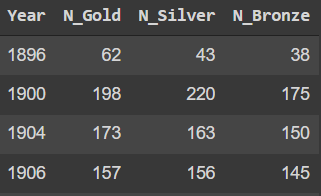

In [10]:
df.groupby("Year")["Medal"].value_counts()

Year  Medal 
1896  Gold       62
      Silver     43
      Bronze     38
1900  Silver    220
      Gold      198
               ... 
2014  Bronze    198
      Silver    197
2016  Bronze    703
      Gold      665
      Silver    655
Name: count, Length: 105, dtype: int64

# <font color='red'>**You are Geek!**</fond>
### Provide all your answers with plots

### Find the number of winners with the gold medal in each city?

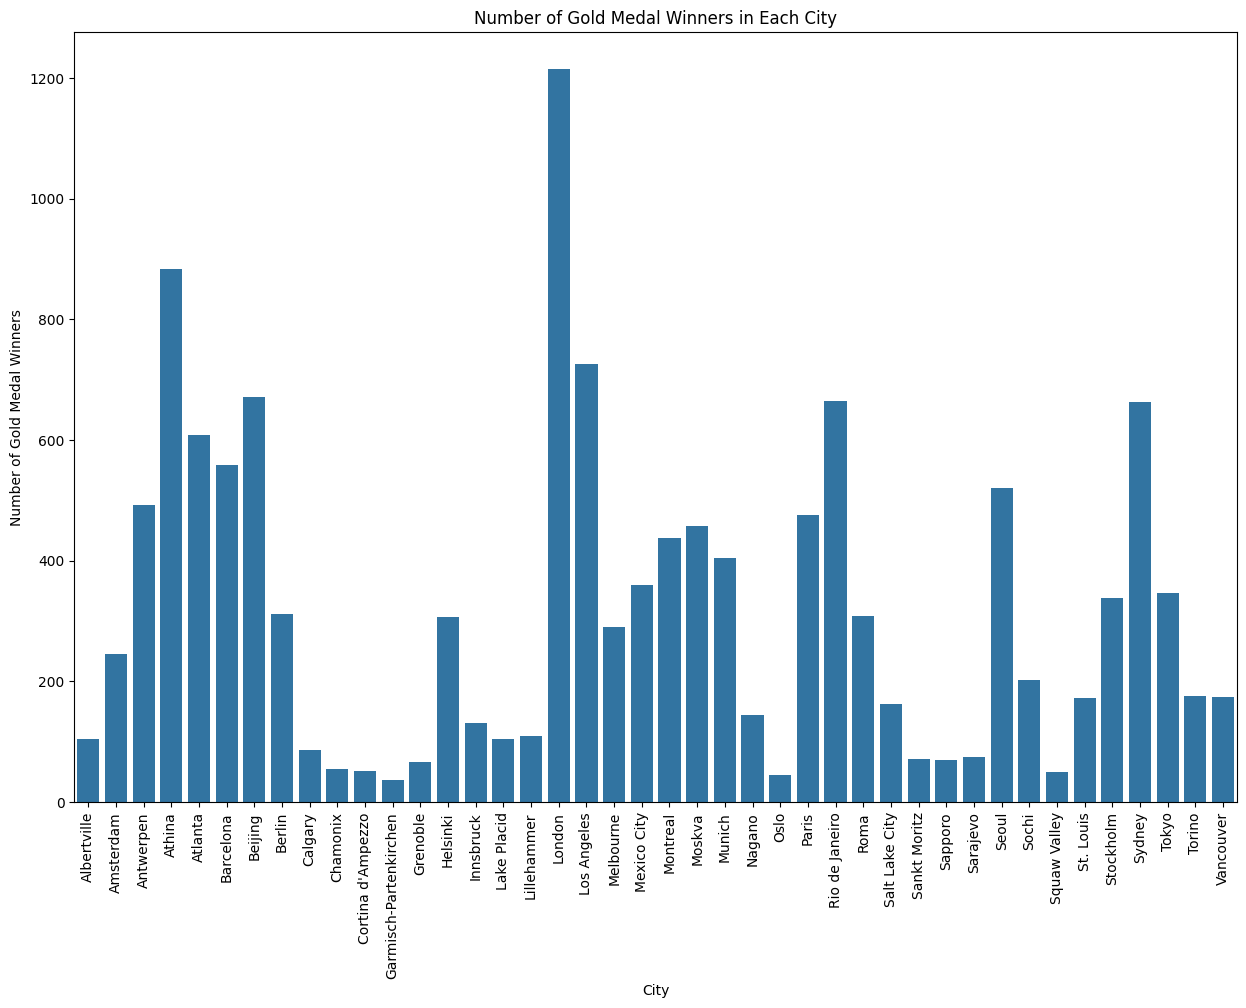

In [11]:
gold_medals = df[df["Medal"] == "Gold"]

plt.figure(figsize=(15, 10))
gold_counts = gold_medals.groupby("City").size()
sns.barplot(x=gold_counts.index, y=gold_counts.values)

plt.title("Number of Gold Medal Winners in Each City")
plt.xlabel("City")
plt.ylabel("Number of Gold Medal Winners")
plt.xticks(rotation=90)
plt.show()

### Find the total missing data for each year?

/tmp/ipykernel_2427/3405729041.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  missing_per_year = df.groupby("Year").apply(lambda x: x.isnull().sum().sum()).reset_index(name="Missing_Count")


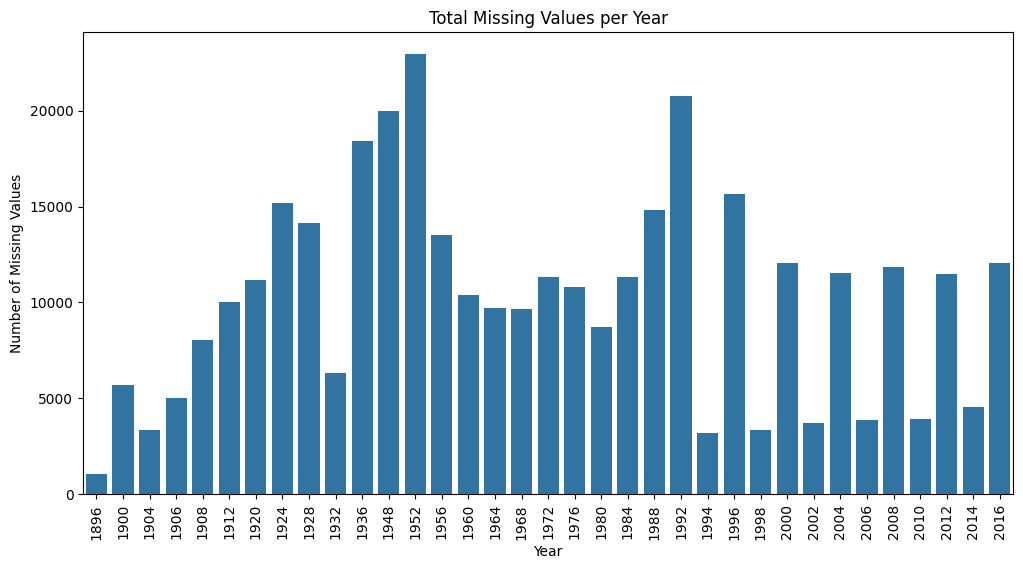

In [12]:
missing_per_year = df.groupby("Year").apply(lambda x: x.isnull().sum().sum()).reset_index(name="Missing_Count")

plt.figure(figsize=(12, 6))

sns.barplot(data=missing_per_year, x="Year", y="Missing_Count")

plt.title("Total Missing Values per Year")
plt.xlabel("Year")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=90)
plt.show()

# <font color='red'>**I dare you to solve this :)**</fond>
### Dont use for loops, and provide all your answers with plots.

### Has the number of athletes changed over time for Summer and Winter?

<Axes: xlabel='Year', ylabel='Athlete_Count'>

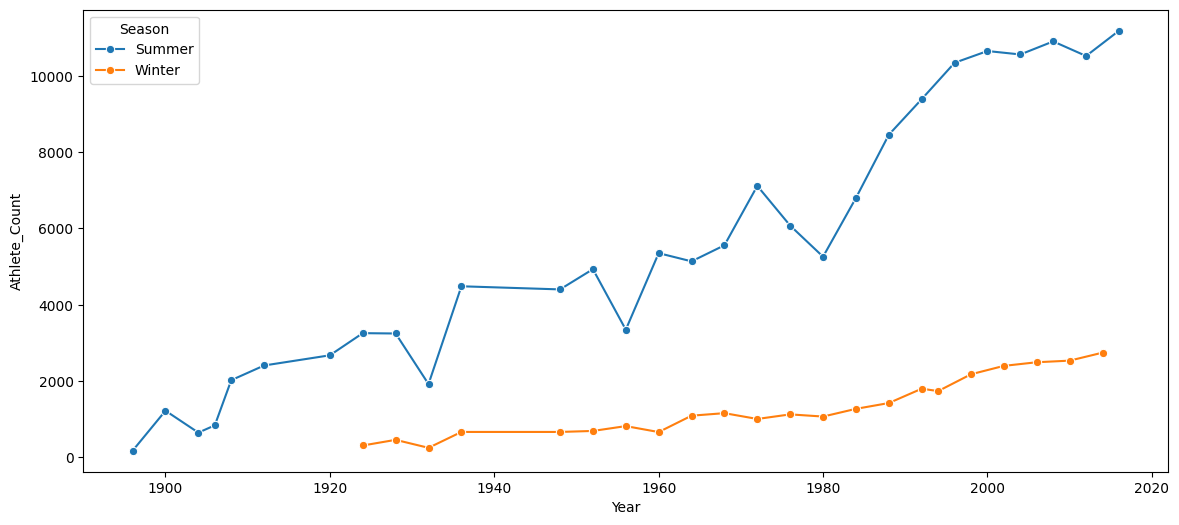

In [13]:
athletes_per_year = df.groupby(["Year", "Season"])["ID"].nunique().reset_index(name="Athlete_Count")

plt.figure(figsize=(14, 6))

sns.lineplot(data=athletes_per_year, x="Year", y="Athlete_Count", hue="Season", marker="o")